# Логистическая регрессия на практике

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.datasets import make_blobs, make_circles, load_digits, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import accuracy_score, log_loss
from sklearn.calibration import calibration_curve

PURPLE, ORANGE, LAV, INK = "#6E62A3", "#EE8A36", "#A097C2", "#1E1E1E"
CMAP = LinearSegmentedColormap.from_list("po", ["#CEC7E6", "#FFFFFF", "#FAD3B2"])
plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "font.size": 11})
rng = np.random.default_rng(0)


def scatter2(ax, X, y, s=30):
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=s, c=PURPLE, label="класс 0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=s, c=ORANGE, marker="s", label="класс 1")


def plot_proba(ax, predict_proba, X, y, levels=(0.1, 0.5, 0.9), pad=0.5):
    x0, x1 = X[:, 0].min() - pad, X[:, 0].max() + pad
    y0, y1 = X[:, 1].min() - pad, X[:, 1].max() + pad
    gx, gy = np.meshgrid(np.linspace(x0, x1, 300), np.linspace(y0, y1, 300))
    P = predict_proba(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.imshow(P, extent=(x0, x1, y0, y1), origin="lower", cmap=CMAP, vmin=0, vmax=1, aspect="auto")
    cs = ax.contour(gx, gy, P, levels=list(levels), colors=INK, linewidths=1.2)
    ax.clabel(cs, fmt="%.1f", fontsize=9)
    scatter2(ax, X, y)

## 1. Почему МНК на метках 0/1 не подходит

Обучим обычную линейную регрессию на метках 0 и 1 и будем отвечать «1», если прогноз больше 0,5. Потом добавим три объекта класса 1 далеко справа — они классифицированы правильно с огромным запасом.

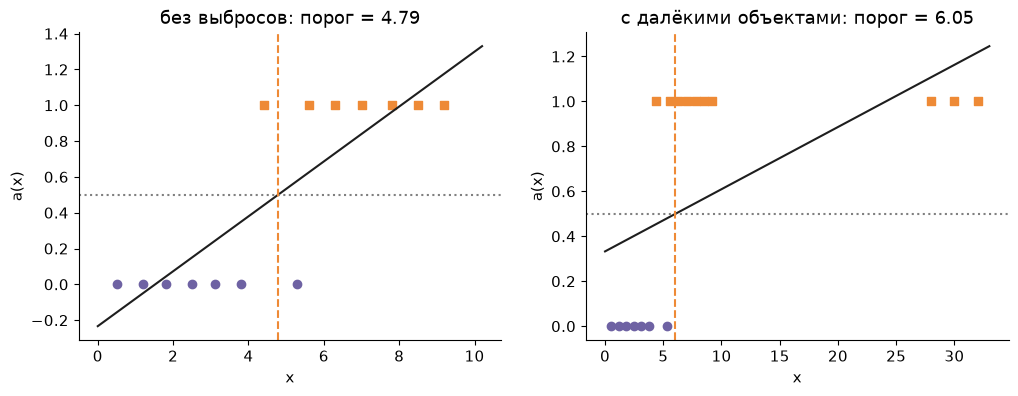

In [33]:
x0 = np.array([0.5, 1.2, 1.8, 2.5, 3.1, 3.8, 5.3])
x1 = np.array([4.4, 5.6, 6.3, 7.0, 7.8, 8.5, 9.2])
far = np.array([28.0, 30.0, 32.0])


def ols_threshold(x, y):
    m = LinearRegression().fit(x[:, None], y)
    return m, (0.5 - m.intercept_) / m.coef_[0]


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, extra in zip(axes, [False, True]):
    xa = np.r_[x0, x1, far] if extra else np.r_[x0, x1]
    ya = np.r_[np.zeros(len(x0)), np.ones(len(xa) - len(x0))]
    m, t = ols_threshold(xa, ya)
    xs = np.linspace(0, xa.max() + 1, 100)
    ax.plot(xs, m.predict(xs[:, None]), color=INK)
    ax.axhline(0.5, ls=":", color="grey"); ax.axvline(t, ls="--", color=ORANGE)
    ax.scatter(xa[ya == 0], ya[ya == 0], c=PURPLE); ax.scatter(xa[ya == 1], ya[ya == 1], c=ORANGE, marker="s")
    ax.set_title(f"{'с далёкими объектами' if extra else 'без выбросов'}: порог = {t:.2f}")
    ax.set_xlabel("x"); ax.set_ylabel("a(x)")
plt.show()

Порог уехал вправо, и объект класса 1 при x = 5,6 теперь классифицируется неверно. Прогнозы к тому же выходят за [0, 1]. Причина — квадратичная потеря штрафует «слишком правильные» объекты (слайд 9).

## 2. Сигмоида и log-loss

Сигмоида переводит любое число в интервал (0, 1). Проверим свойства со слайда 14 численно.

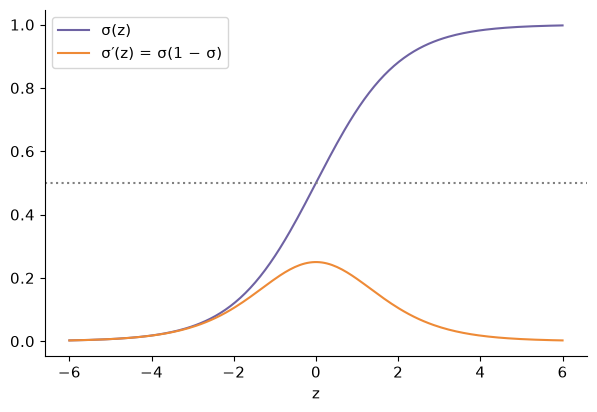

σ(−z) = 1 − σ(z): True
σ′ = σ(1 − σ):   True


In [34]:
z = np.linspace(-6, 6, 200)
s = 1 / (1 + np.exp(-z))
plt.plot(z, s, color=PURPLE, label="σ(z)")
plt.plot(z, s * (1 - s), color=ORANGE, label="σ′(z) = σ(1 − σ)")
plt.axhline(0.5, ls=":", color="grey"); plt.legend(); plt.xlabel("z"); plt.show()

print("σ(−z) = 1 − σ(z):", np.allclose(1 / (1 + np.exp(z)), 1 - s))
# производная численно против формулы
h = 1e-5
num = (1 / (1 + np.exp(-(z + h))) - 1 / (1 + np.exp(-(z - h)))) / (2 * h)
print("σ′ = σ(1 − σ):  ", np.allclose(num, s * (1 - s)))

### Задание 1 — сигмоида и log-loss своими руками

Допишите две функции:

1. `sigmoid(z)` — сигмоида σ(z) = 1 / (1 + e^(−z)). Должна работать и для чисел, и для массивов numpy.
2. `my_log_loss(y, p)` — средний log-loss по выборке:

   L = −(1/n) · Σ [ yᵢ · log pᵢ + (1 − yᵢ) · log(1 − pᵢ) ]

Подсказка: чтобы не получить log(0), ограничьте вероятности: `p = np.clip(p, 1e-15, 1 - 1e-15)`.

In [35]:
def sigmoid(z):
    return 1 / (1 + np.pow(np.e, -z))

def my_log_loss(y, p):
    y = np.array(y)
    p = np.array(p)
    return (-1 / len(y)) * np.sum(y @ np.log(p) + (1 - y) @ np.log(1 - p))

In [36]:

assert abs(sigmoid(0) - 0.5) < 1e-9
assert np.allclose(sigmoid(np.array([-2.0, 3.0])), [0.1192, 0.9526], atol=1e-4)
assert abs(my_log_loss([1], [0.9]) - 0.105) < 1e-3
assert abs(my_log_loss([0], [0.1]) - 0.105) < 1e-3   
assert abs(my_log_loss([1], [0.01]) - 4.605) < 1e-3
assert abs(my_log_loss([1, 0, 1, 0], [0.5] * 4) - np.log(2)) < 1e-9 
print("Верно!")

Верно!


## 3. Логистическая регрессия своими руками

Градиент log-loss — «ошибка × признак»: ∇L = Xᵀ(p − y) / n (делим на n, потому что минимизируем среднее). Свободный член добавим как столбец единиц.

веса (w0, w1, w2): [-0.258  1.912  1.557]


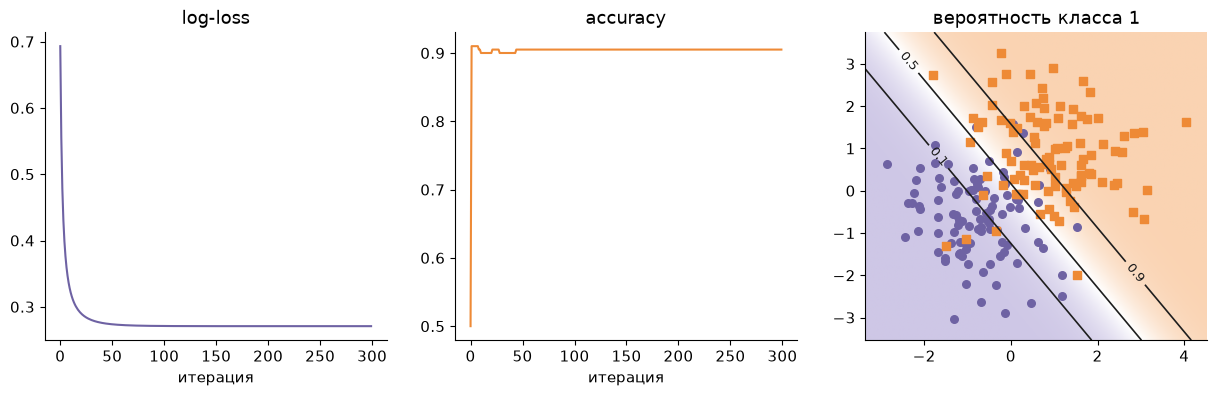

In [37]:
X, y = make_blobs(n_samples=200, centers=[[-1, -0.6], [1, 0.8]], cluster_std=1.0, random_state=1)
A = np.c_[np.ones(len(X)), X]          # столбец единиц для свободного члена w0


def sig(z):
    return 1 / (1 + np.exp(-z))

def fit_gd(A, y, lr=0.5, n_iter=300):
    w = np.zeros(A.shape[1])
    history = []
    for t in range(n_iter):
        p = sig(A @ w)
        history.append((log_loss(y, p), accuracy_score(y, p > 0.5)))
        w -= lr * A.T @ (p - y) / len(y)        # шаг градиентного спуска
    return w, np.array(history)


w_gd, hist = fit_gd(A, y)
print("веса (w0, w1, w2):", w_gd.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(hist[:, 0], color=PURPLE); axes[0].set_title("log-loss"); axes[0].set_xlabel("итерация")
axes[1].plot(hist[:, 1], color=ORANGE); axes[1].set_title("accuracy"); axes[1].set_xlabel("итерация")
plot_proba(axes[2], lambda Z: sig(np.c_[np.ones(len(Z)), Z] @ w_gd), X, y)
axes[2].set_title("вероятность класса 1")
plt.show()

Accuracy выходит на плато за десяток итераций, а log-loss продолжает падать — модель уточняет вероятности (слайд 27). Линии уровня вероятности параллельны границе (слайд 30).

Сравним со sklearn. `C=1e10` — практически без регуляризации, иначе sklearn по умолчанию добавляет L2 (C = 1).

In [38]:
sk = LogisticRegression(C=1e10, tol=1e-10, max_iter=5000).fit(X, y)
print("sklearn:   ", np.r_[sk.intercept_, sk.coef_.ravel()].round(3))

w_long, _ = fit_gd(A, y, lr=0.5, n_iter=5000)
print("наш GD:    ", w_long.round(3))

sklearn:    [-0.258  1.914  1.558]
наш GD:     [-0.258  1.914  1.558]


### Условие оптимума

В оптимуме Xᵀ(p − y) = 0. Для столбца единиц это значит: средняя предсказанная вероятность равна доле класса 1.

In [39]:
p = sk.predict_proba(X)[:, 1]
print("средняя p:      ", p.mean().round(4))
print("доля класса 1:  ", y.mean().round(4))
print("Xᵀ(p − y) =", (A.T @ (p - y)).round(4))

средняя p:       0.5
доля класса 1:   0.5
Xᵀ(p − y) = [ 0.  0. -0.]


### Метод Ньютона

Шаг Ньютона: w ← w − H⁻¹∇L, где H = XᵀSX, S = diag(pᵢ(1 − pᵢ)). Сравним скорость с градиентным спуском.

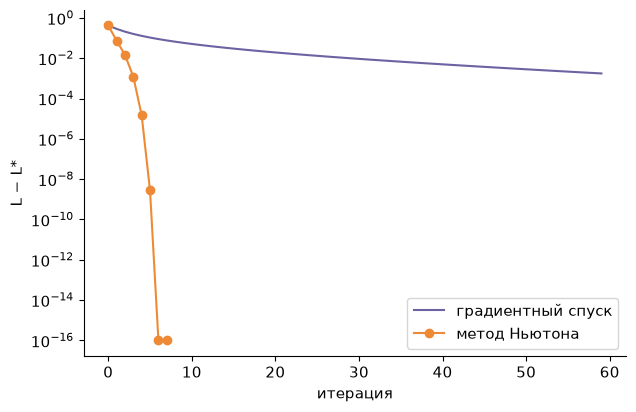

In [40]:
w_star = np.r_[sk.intercept_, sk.coef_.ravel()]
L_star = log_loss(y, sig(A @ w_star))

w = np.zeros(3); newton = []
for t in range(8):
    p = sig(A @ w)
    newton.append(log_loss(y, p) - L_star)
    grad = A.T @ (p - y) / len(y)
    H = (A.T * (p * (1 - p))) @ A / len(y)
    w -= np.linalg.solve(H, grad)

_, hist = fit_gd(A, y, lr=0.5, n_iter=60)
plt.semilogy(np.maximum(hist[:, 0] - L_star, 1e-16), color=PURPLE, label="градиентный спуск")
plt.semilogy(np.maximum(newton, 1e-16), "o-", color=ORANGE, label="метод Ньютона")
plt.xlabel("итерация"); plt.ylabel("L − L*"); plt.legend(); plt.show()

### Задание 2 — один шаг градиентного спуска

Повторите пример со слайда 28 в коде. Данные одномерные, без свободного члена:

| x | y |
|---|---|
| 1 | 1 |
| 2 | 1 |
| −1 | 0 |

Старт w = 0, шаг η = 0,5. Градиент — **сумма** (pᵢ − yᵢ)·xᵢ (без деления на n, как на слайде).

Посчитайте: `grad` — градиент в точке w = 0, `w_new` — вес после шага, `loss_new` — log-loss **в сумме** по трём объектам после шага (можно взять `3 * my_log_loss(...)`).

In [41]:
x = np.array([1.0, 2.0, -1.0])
y2 = np.array([1.0, 1.0, 0.0])
w = 0.0
eta = 0.5

grad = ...       # ваш код здесь
w_new = ...      # ваш код здесь
loss_new = ...   # ваш код здесь
print("grad =", grad, " w_new =", w_new, " loss_new =", loss_new)

grad = Ellipsis  w_new = Ellipsis  loss_new = Ellipsis


In [42]:
# Проверка задания 2
assert abs(grad - (-2)) < 1e-9, "градиент должен быть −2"
assert abs(w_new - 1) < 1e-9, "после шага w = 1"
assert abs(loss_new - 0.753) < 1e-2, "log-loss после шага ≈ 0,75"
print("Верно!")

TypeError: unsupported operand type(s) for -: 'ellipsis' and 'int'

## 4. MSE поверх сигмоиды против log-loss

Сравним производные по z для уверенно ошибочного объекта (y = 1, z сильно отрицательный).

In [ ]:
for z in [-1, -3, -6]:
    s = sig(z)
    print(f"z = {z:>3}:  MSE поверх σ: {2 * (s - 1) * s * (1 - s):+.5f}    log-loss: {s - 1:+.5f}")

Чем грубее ошибка, тем слабее сигнал у MSE поверх σ — и тем сильнее у log-loss.

## 5. Выбросы больше не страшны

Возьмём данные из раздела 1 с далёкими объектами и обучим логистическую регрессию.

In [ ]:
xa = np.r_[x0, x1, far]; ya = np.r_[np.zeros(len(x0)), np.ones(len(x1) + len(far))]
m_ols, t_ols = ols_threshold(xa, ya)
m_log = LogisticRegression(C=1e10).fit(xa[:, None], ya)
t_log = -m_log.intercept_[0] / m_log.coef_[0, 0]

xs = np.linspace(0, 34, 400)
plt.plot(xs, m_ols.predict(xs[:, None]), color=INK, label=f"МНК, порог {t_ols:.2f}")
plt.plot(xs, m_log.predict_proba(xs[:, None])[:, 1], color=PURPLE, label=f"логрег, граница {t_log:.2f}")
plt.scatter(xa[ya == 0], ya[ya == 0], c=PURPLE); plt.scatter(xa[ya == 1], ya[ya == 1], c=ORANGE, marker="s")
plt.axhline(0.5, ls=":", color="grey"); plt.ylim(-0.3, 1.5); plt.legend(); plt.show()

p_far = m_log.predict_proba(far[:, None])[:, 1]
print("p у далёких объектов:", p_far.round(4), " их вклад (p − y)·x:", ((p_far - 1) * far).round(4))

## 6. Норма весов, разделимые данные, L2

### Норма весов — уверенность

Умножим все веса на c: граница та же, accuracy та же, а log-loss разный.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, [0.3, 1, 5]):
    wc = c * w_star
    p = sig(A @ wc)
    plot_proba(ax, lambda Z, wc=wc: sig(np.c_[np.ones(len(Z)), Z] @ wc), X, y, levels=(0.5,))
    ax.set_title(f"c = {c}: accuracy {accuracy_score(y, p > 0.5):.2f}, log-loss {log_loss(y, p):.3f}")
plt.show()

### Разделимые данные: веса растут бесконечно

Если классы можно разделить прямой, минимума log-loss нет — градиентный спуск всё время увеличивает ‖w‖.

In [ ]:
Xs, ys = make_blobs(n_samples=80, centers=[[-1.5, -1], [1.5, 1]], cluster_std=0.5, random_state=3)
As = np.c_[np.ones(len(Xs)), Xs]

w = np.zeros(3); norms = []
for t in range(1, 20001):
    w -= 1.0 * As.T @ (sig(As @ w) - ys) / len(ys)
    if t in (10, 100, 1000, 10000, 20000):
        norms.append((t, np.linalg.norm(w[1:]), log_loss(ys, sig(As @ w))))
for t, nrm, ll in norms:
    print(f"итерация {t:>6}:  ‖w‖ = {nrm:6.2f}   log-loss = {ll:.6f}")

### L2-регуляризация возвращает минимум

В sklearn сила регуляризации задаётся через C = 1/λ: чем меньше C, тем сильнее штраф и тем меньше ‖w‖.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, C in zip(axes, [100, 1, 0.05]):
    m = LogisticRegression(C=C).fit(Xs, ys)
    plot_proba(ax, lambda Z, m=m: m.predict_proba(Z)[:, 1], Xs, ys)
    ax.set_title(f"C = {C}:  ‖w‖ = {np.linalg.norm(m.coef_):.2f}")
plt.show()

## 7. Нелинейные границы через признаки

«Кольцо»: класс 1 внутри окружности. Линейная модель на исходных признаках не справляется.

In [ ]:
Xc, yc = make_circles(n_samples=300, factor=0.4, noise=0.08, random_state=0)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.3, random_state=0)

lin = LogisticRegression().fit(Xc_tr, yc_tr)
print("accuracy на исходных признаках:", round(accuracy_score(yc_te, lin.predict(Xc_te)), 3))

fig, ax = plt.subplots(figsize=(5, 5))
plot_proba(ax, lambda Z: lin.predict_proba(Z)[:, 1], Xc, yc, levels=(0.5,)); ax.set_aspect("equal"); plt.show()

### Задание 3 — признак, который «разгибает» кольцо

Добавьте к двум признакам третий: **r² = x₁² + x₂²** (квадрат расстояния до центра). Обучите `LogisticRegression` на трёх признаках и добейтесь accuracy на тесте **не ниже 0,95**.

Подсказка: `np.c_[X, новый_столбец]` приклеивает столбец к матрице.

In [ ]:
def add_r2(X):
    # ваш код здесь: вернуть матрицу с тремя столбцами x1, x2, x1² + x2²
    ...


model3 = ...   # ваш код здесь
acc3 = ...     # ваш код здесь
print("accuracy:", acc3)

In [ ]:
# Проверка задания 3
assert add_r2(Xc_tr).shape[1] == 3, "должно быть три признака"
assert acc3 >= 0.95, f"accuracy {acc3:.3f} — пока меньше 0,95"
print("Верно!")

fig, ax = plt.subplots(figsize=(5, 5))
plot_proba(ax, lambda Z: model3.predict_proba(add_r2(Z))[:, 1], Xc, yc, levels=(0.5,)); ax.set_aspect("equal"); plt.show()

Граница в исходных координатах — окружность, хотя модель по-прежнему линейна по весам. Тот же эффект даёт `PolynomialFeatures(degree=2)`, но признаков получается больше:

In [ ]:
poly = PolynomialFeatures(degree=2, include_bias=False)
m_poly = LogisticRegression().fit(poly.fit_transform(Xc_tr), yc_tr)
print("признаков:", poly.n_output_features_, " accuracy:", round(accuracy_score(yc_te, m_poly.predict(poly.transform(Xc_te))), 3))

## 8. Много классов: softmax
Рукописные цифры 8×8 пикселей, 10 классов. `LogisticRegression` для нескольких классов по умолчанию обучает softmax-регрессию.

In [ ]:
digits = load_digits()
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(digits.data, digits.target, test_size=0.3, random_state=0)
scaler_d = StandardScaler().fit(Xd_tr)
soft = LogisticRegression(max_iter=2000).fit(scaler_d.transform(Xd_tr), yd_tr)
print("accuracy на тесте:", round(accuracy_score(yd_te, soft.predict(scaler_d.transform(Xd_te))), 3))
print("форма матрицы весов:", soft.coef_.shape, "— свой вектор весов у каждого класса")

i = 5
proba = soft.predict_proba(scaler_d.transform(Xd_te[i:i + 1]))[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={"width_ratios": [1, 3]})
axes[0].imshow(Xd_te[i].reshape(8, 8), cmap="gray_r"); axes[0].set_title(f"верный ответ: {yd_te[i]}"); axes[0].axis("off")
axes[1].bar(range(10), proba, color=LAV); axes[1].set_xticks(range(10)); axes[1].set_title(f"вероятности, сумма = {proba.sum():.3f}")
plt.show()

Проверим, что `predict_proba` — это действительно softmax от score zₖ = ⟨wₖ, x⟩ + bₖ, и посмотрим на температуру (слайд 38).

In [ ]:
def softmax(z, T=1.0):
    z = np.asarray(z, float) / T
    e = np.exp(z - z.max())          # вычитаем максимум, чтобы не было переполнения
    return e / e.sum()


z = soft.decision_function(scaler_d.transform(Xd_te[i:i + 1]))[0]
print("совпадает с predict_proba:", np.allclose(softmax(z), proba))

for T in [0.3, 1, 3]:
    print(f"T = {T}:", softmax([2, 1, 0.1], T).round(2))